# DeepEval results: architecture and thinking-mode comparison

This notebook compares the 24 setup variants (S1–S8 × variants a–d) on the DeepEval scores in
`results/deepeval/scored_merged_dedup.csv`, and tests the two study hypotheses from `EXPERIMENT.md`:

| | Hypothesis | Setups | What we measure |
|---|---|---|---|
| **H1** | Letting agents make their own tool calls is more flexible and might be faster | S1–S4 (agentic) | Wall-clock latency, LLM calls, tokens; metric pass rates on the non-routine cases; tool-path diversity |
| **H2** | A deterministic, code-controlled flow succeeds more often | S5–S8 (graph) | Pass rate and mean score on each of the eight DeepEval metrics |

**Design.** Each agentic setup has a graph counterpart that differs *only* in control style:
S1↔S5, S2↔S6, S3↔S7, S4↔S8, with the same variant letter. Each of the 13 cases was run once per variant,
which gives **12 matched variant pairs × 13 cases = 156 paired observations**. The control-style tests below use
these pairs (Wilcoxon signed-rank for scores and latency, exact McNemar for pass/fail). That removes case difficulty,
agent count, policy mode and strategy from the comparison.

**Thinking modes** (the variants): `react` picks one step at a time; `plan_execute` plans every step up front and
replans only on an error. Multi-agent variants c and d mix the two strategies between supervisor and specialists.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

# Repo root, found whether the notebook runs from results/deepeval or the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "EXPERIMENT.md").exists())
CSV = ROOT / "results/deepeval/scored_merged_dedup.csv"
RAW_DIR = ROOT / "deepeval"
FIG_DIR = ROOT / "results/deepeval/figures"
FIG_DIR.mkdir(exist_ok=True)

# Colours: categorical slot 1 (blue) = agentic, slot 2 (orange) = graph; one-hue ramp for heatmaps
C_AGENTIC, C_GRAPH = "#2a78d6", "#eb6834"
CONTROL_PAL = {"agentic": C_AGENTIC, "graph": C_GRAPH}
SEQ = sns.light_palette("#2a78d6", as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9, "legend.frameon": False,
    "lines.linewidth": 2,
})

## 1. Load and label the data

In [2]:
df = pd.read_csv(CSV)

df["family"] = df["setup"].str[:2].str.upper()           # S1..S8
df["variant"] = df["setup"].str[-1]                      # a..d
fam_num = df["family"].str[1].astype(int)
df["control"] = np.where(fam_num <= 4, "agentic", "graph")
df["agents"] = np.where(fam_num.isin([1, 2, 5, 6]), "single", "multi")
df["policy"] = np.where(fam_num % 2 == 1, "RAG", "SKILL")

SINGLE_STRAT = {"a": "react", "b": "plan_execute"}
MULTI_STRAT = {"a": "react / react", "b": "plan / plan", "c": "react / plan", "d": "plan / react"}
df["strategy"] = np.where(df["agents"] == "single", df["variant"].map(SINGLE_STRAT), df["variant"].map(MULTI_STRAT))
# The "thinking mode" of whoever makes the tool calls (the agent, or the specialists in multi-agent setups)
df["worker_strategy"] = df["variant"].map({"a": "react", "b": "plan_execute", "c": "plan_execute", "d": "react"})

# Matched pair across control style: same agent count, policy and variant (S1-a <-> S5-a, ...)
df["pair_id"] = df["agents"] + "-" + df["policy"] + "-" + df["variant"]
df["arch"] = df["agents"] + " · " + df["control"]

df[["setup", "family", "variant", "control", "agents", "policy", "strategy", "pair_id"]].drop_duplicates().reset_index(drop=True)

,setup,family,variant,control,agents,policy,strategy,pair_id
0,s1-a,S1,a,agentic,single,RAG,react,single-RAG-a
1,s1-b,S1,b,agentic,single,RAG,plan_execute,single-RAG-b
2,s2-a,S2,a,agentic,single,SKILL,react,single-SKILL-a
3,s2-b,S2,b,agentic,single,SKILL,plan_execute,single-SKILL-b
4,s3-a,S3,a,agentic,multi,RAG,react / react,multi-RAG-a
5,s3-b,S3,b,agentic,multi,RAG,plan / plan,multi-RAG-b
6,s3-c,S3,c,agentic,multi,RAG,react / plan,multi-RAG-c
7,s3-d,S3,d,agentic,multi,RAG,plan / react,multi-RAG-d
8,s4-a,S4,a,agentic,multi,SKILL,react / react,multi-SKILL-a
9,s4-b,S4,b,agentic,multi,SKILL,plan / plan,multi-SKILL-b


### 1a. Join latency and cost from the raw run logs

The scored CSV has no timing, so latency, LLM calls, tokens and tool calls come from the raw run JSONL files in
`deepeval/`. A multi-turn case (EVAL-12, EVAL-13) has one `workflow_end` event per turn; those are summed.

EVAL-01 was run twice for every setup in `results.jsonl`, and the deduped CSV kept the **later** run, so we keep the last
raw row per (case, setup, source). The assert checks that every scored row found its run and that ticket statuses agree.

In [3]:
SOURCES = {"results.jsonl": "scored",
           "new_cases_results_all.jsonl": "new_cases_results_all",
           "new_cases_results_errors_retry.jsonl": "errors_retry"}

def summarise_run(row):
    events = row["trace"].get("events", [])
    ends = [e for e in events if e["kind"] == "workflow_end"]
    calls = [e for e in events if e["kind"] == "llm_call"]
    return {
        "case_id": row["case_id"], "setup": row["setup"],
        "raw_status": row["ticket_status"],
        "elapsed_s": sum(e.get("elapsed_s", 0) for e in ends),
        "llm_calls": sum(e.get("llm_calls", 0) for e in ends),
        "input_tokens": sum(e.get("input_tokens", 0) for e in calls),
        "output_tokens": sum(e.get("output_tokens", 0) for e in calls),
        "tool_calls": len(row["tools_called"]),
        "tool_path": " > ".join(t["name"] for t in row["tools_called"]),
        "write_count": len(row.get("writes") or []),
        "models": ",".join(sorted({e.get("model", "?") for e in calls})),
        "turns": len(ends),
    }

raw = []
for fname, source in SOURCES.items():
    for i, line in enumerate((RAW_DIR / fname).open()):
        rec = summarise_run(json.loads(line)) | {"source_file": source, "run_idx": i}
        raw.append(rec)
raw = pd.DataFrame(raw)

key = ["case_id", "setup", "source_file"]
raw = raw.sort_values("run_idx")
raw_kept = raw.drop_duplicates(key, keep="last")

df = df.merge(raw_kept.drop(columns="run_idx"), on=key, how="left", validate="one_to_one")
assert df["elapsed_s"].notna().all(), "a scored row has no raw run"
assert (df["raw_status"] == df["ticket_status"]).all(), "raw and scored ticket statuses disagree"
df["total_tokens"] = df["input_tokens"] + df["output_tokens"]

print(f"{len(df)} scored rows = {df.setup.nunique()} setups × {df.case_id.nunique()} cases")
print("Agent LLM(s) used:", df["models"].value_counts().to_dict())

312 scored rows = 24 setups × 13 cases
Agent LLM(s) used: {'openai/gpt-oss-120b': 312}


### 1b. Case catalogue

In [4]:
cases = pd.concat([pd.read_csv(RAW_DIR / "cases_original.csv"), pd.read_csv(RAW_DIR / "cases.csv")])
cases = cases.drop_duplicates("case_id", keep="last").set_index("case_id")[["focus", "expected_ticket_status"]].sort_index()

# Routine single-lookup cases vs the cases that need the agent to adapt (writes, safety, injection, clarification, replay)
ROUTINE = [f"EVAL-0{i}" for i in range(1, 9)]
cases["kind"] = np.where(cases.index.isin(ROUTINE), "routine lookup", "non-routine")
df = df.merge(cases[["focus", "kind"]], left_on="case_id", right_index=True)
cases

,focus,expected_ticket_status,kind
case_id,,,
EVAL-01,Order contents lookup: items in the power-bank...,resolved,routine lookup
EVAL-02,Order status lookup: processing order,resolved,routine lookup
EVAL-03,Payment lookup: captured payment status,resolved,routine lookup
EVAL-04,Return lookup: pending fault claim status,resolved,routine lookup
EVAL-05,Tracking lookup: delivered shipment status,resolved,routine lookup
EVAL-06,Policy lookup: ordinary return request window,resolved,routine lookup
EVAL-07,Customer order lookup: identify processing order,resolved,routine lookup
EVAL-08,Shipment lookup: carrier and tracking number,resolved,routine lookup
EVAL-09,"Refund processing: approved bottle return, SGD 20",resolved,non-routine


## 2. The metrics

Every comparison below uses the eight DeepEval metrics in the CSV, each reported two ways:

- **Pass rate:** the share of runs that pass, from the manual labels (`<metric>_success_manual`).
- **Mean score:** the judge's raw 0–1 score (`<metric>_score`).

| Metric | What the judge checks | Scored for |
|---|---|---|
| answer correctness | The reply answers the request, agrees with the ground truth and invents nothing | all runs |
| tool correctness | The right tools were called, in the right order | all runs |
| argument correctness | The tool calls used the right arguments | all runs |
| task completion | The trace shows the task done (a write only counts if it succeeded) | all runs |
| step efficiency | Only relevant steps; no loops, repeats or invented IDs | all runs |
| trajectory quality | Evidence used correctly; policy and write safeguards followed | all runs |
| plan adherence | Execution followed the plan | plan_execute variants only (b, c, d) |
| plan quality | The plan was complete, ordered and safe | plan_execute variants only (b, c, d) |

The CSV also records the final ticket status and the expected one, so **ticket status** is shown alongside as a
supplementary check. It is not a DeepEval metric.

**Why manual labels.** The judge's own `_success` flags are not reliable: for several G-Eval metrics a score of 1.0 is
often flagged `False` (first table). Where a row has no manual label, it falls back to **score ≥ 0.5**, DeepEval's
default threshold. The second table shows where the manual labels differ from that rule; the third lists the rows
that fell back to it.

In [5]:
CORE = ["answer_correctness", "tool_correctness", "argument_correctness",
        "task_completion_trace", "step_efficiency_trace", "trajectory_quality_trace"]
PLAN = ["plan_adherence_trace", "plan_quality_trace"]
METRICS = CORE + PLAN
SHORT = {"answer_correctness": "answer", "tool_correctness": "tool", "argument_correctness": "argument",
         "task_completion_trace": "task completion", "step_efficiency_trace": "step efficiency",
         "trajectory_quality_trace": "trajectory", "plan_adherence_trace": "plan adherence",
         "plan_quality_trace": "plan quality", "status_ok": "ticket status"}
THRESH = 0.5

flag_check = pd.DataFrame({
    SHORT[m]: {"score ≥ 0.5 but flagged False": ((df[f"{m}_score"] >= THRESH) & (df[f"{m}_success"].astype(str) == "False")).sum(),
               "score < 0.5 but flagged True": ((df[f"{m}_score"] < THRESH) & (df[f"{m}_success"].astype(str) == "True")).sum()}
    for m in METRICS}).T
display(flag_check)

def to_bool(col):
    return col.map({True: True, False: False, "True": True, "False": False})

overrides, fallback = {}, set()
for m in METRICS:
    score_rule = (df[f"{m}_score"] >= THRESH).where(df[f"{m}_score"].notna())
    manual = to_bool(df[f"{m}_success_manual"])
    has_score = df[f"{m}_score"].notna()
    both = manual.notna() & has_score
    overrides[SHORT[m]] = {
        "manual pass, score < 0.5": int((both & manual.eq(True) & score_rule.eq(False)).sum()),
        "manual fail, score ≥ 0.5": int((both & manual.eq(False) & score_rule.eq(True)).sum()),
        "no manual label → score rule": int((manual.isna() & has_score).sum()),
    }
    fallback |= set(df.index[manual.isna() & has_score])
    # 1.0 = pass, 0.0 = fail, NaN = metric not scored for this run (whatever the manual column says)
    df[f"{m}_pass"] = manual.where(manual.notna(), score_rule).where(has_score).astype(float)
display(pd.DataFrame(overrides).T)
display(df.loc[sorted(fallback), ["case_id", "setup", "answer_correctness_score", "task_completion_trace_score"]])

df["status_ok"] = (df["ticket_status"] == df["expected_ticket_status"]).astype(float)

PASS_COLS = [f"{m}_pass" for m in METRICS] + ["status_ok"]
SCORE_COLS = [f"{m}_score" for m in METRICS]
label = lambda c: SHORT[c.removesuffix("_pass").removesuffix("_score")]
print("Overall pass rates:", {label(c): f"{df[c].mean():.0%}" for c in PASS_COLS})

,score ≥ 0.5 but flagged False,score < 0.5 but flagged True
answer,73,0
tool,0,0
argument,0,0
task completion,39,0
step efficiency,71,0
trajectory,129,0
plan adherence,28,0
plan quality,42,0


,"manual pass, score < 0.5","manual fail, score ≥ 0.5",no manual label → score rule
answer,0,0,1
tool,0,0,1
argument,7,0,1
task completion,1,0,1
step efficiency,0,0,1
trajectory,0,0,1
plan adherence,0,0,1
plan quality,0,0,1


,case_id,setup,answer_correctness_score,task_completion_trace_score
294,EVAL-13,s3-c,0.2,0.2


Overall pass rates: {'answer': '78%', 'tool': '96%', 'argument': '89%', 'task completion': '87%', 'step efficiency': '96%', 'trajectory': '88%', 'plan adherence': '92%', 'plan quality': '97%', 'ticket status': '94%'}


## 3. Every architecture and variant on every metric

### 3a. Pass rate per setup variant

Rows are the 24 variants in setup order; columns are the metrics. The colour scale starts at 50%, since every
pass rate falls between 69% and 100%. The plan metrics are blank for variant a, which
has no plan. Every cell is out of 13 runs, so one run is worth about 8 points.

In [6]:
order = sorted(df.setup.unique())
meta = df.drop_duplicates("setup").set_index("setup")[["control", "agents", "policy", "strategy"]].loc[order]

pass_by_setup = df.groupby("setup")[PASS_COLS].mean().loc[order].rename(columns=label)
score_by_setup = df.groupby("setup")[SCORE_COLS].mean().loc[order].rename(columns=label)

(meta.join(pass_by_setup).style
     .format("{:.0%}", subset=list(pass_by_setup.columns), na_rep="–")
     .background_gradient(cmap=SEQ, vmin=0, vmax=1, subset=list(pass_by_setup.columns)))

,control,agents,policy,strategy,answer,tool,argument,task completion,step efficiency,trajectory,plan adherence,plan quality,ticket status
setup,,,,,,,,,,,,,
s1-a,agentic,single,RAG,react,77%,92%,92%,92%,92%,69%,–,–,92%
s1-b,agentic,single,RAG,plan_execute,85%,100%,92%,92%,92%,85%,100%,100%,100%
s2-a,agentic,single,SKILL,react,85%,92%,92%,85%,100%,85%,–,–,100%
s2-b,agentic,single,SKILL,plan_execute,85%,100%,85%,100%,100%,100%,100%,100%,92%
s3-a,agentic,multi,RAG,react / react,69%,100%,85%,77%,100%,92%,–,–,85%
s3-b,agentic,multi,RAG,plan / plan,77%,92%,92%,77%,92%,92%,100%,100%,85%
s3-c,agentic,multi,RAG,react / plan,77%,100%,92%,77%,100%,92%,92%,100%,92%
s3-d,agentic,multi,RAG,plan / react,85%,100%,85%,85%,100%,85%,92%,100%,100%
s4-a,agentic,multi,SKILL,react / react,85%,92%,92%,85%,92%,92%,–,–,92%


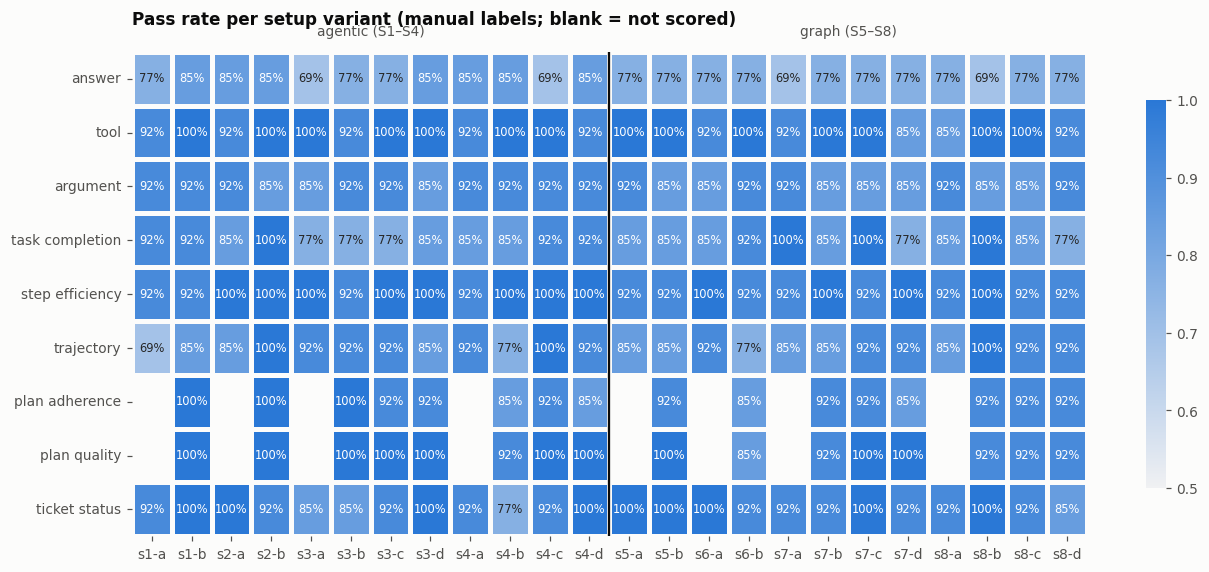

In [7]:
def setup_heatmap(data, title, fname, fmt, vmin):
    fig, ax = plt.subplots(figsize=(14, 0.48 * data.shape[1] + 1.4))
    sns.heatmap(data.T, cmap=SEQ, vmin=vmin, vmax=1, annot=True, fmt=fmt, annot_kws={"size": 7.5},
                linewidths=2, linecolor="#fcfcfb", cbar_kws={"shrink": 0.8}, ax=ax)
    ax.axvline(12, color=INK, lw=1.5)
    ax.text(6, -0.3, "agentic (S1–S4)", ha="center", color=INK2)
    ax.text(18, -0.3, "graph (S5–S8)", ha="center", color=INK2)
    ax.set(xlabel="", ylabel="")
    ax.grid(False)
    ax.set_title(title, pad=18)
    fig.savefig(FIG_DIR / fname)

setup_heatmap(pass_by_setup, "Pass rate per setup variant (manual labels; blank = not scored)", "pass_rate_heatmap.png", ".0%", vmin=0.5)

### 3b. Mean judge score per setup variant

,control,agents,policy,strategy,answer,tool,argument,task completion,step efficiency,trajectory,plan adherence,plan quality
setup,,,,,,,,,,,,
s1-a,agentic,single,RAG,react,0.75,0.87,0.88,0.89,0.89,0.74,–,–
s1-b,agentic,single,RAG,plan_execute,0.75,0.97,0.86,0.94,0.86,0.83,0.99,0.98
s2-a,agentic,single,SKILL,react,0.75,0.89,0.86,0.87,0.98,0.85,–,–
s2-b,agentic,single,SKILL,plan_execute,0.77,0.95,0.79,0.96,0.97,0.88,0.99,0.99
s3-a,agentic,multi,RAG,react / react,0.67,0.89,0.87,0.77,0.87,0.89,–,–
s3-b,agentic,multi,RAG,plan / plan,0.68,0.90,0.88,0.81,0.87,0.89,0.92,0.96
s3-c,agentic,multi,RAG,react / plan,0.74,0.92,0.90,0.81,0.90,0.92,0.90,0.97
s3-d,agentic,multi,RAG,plan / react,0.70,0.92,0.85,0.82,0.88,0.83,0.93,0.98
s4-a,agentic,multi,SKILL,react / react,0.75,0.92,0.79,0.86,0.88,0.85,–,–


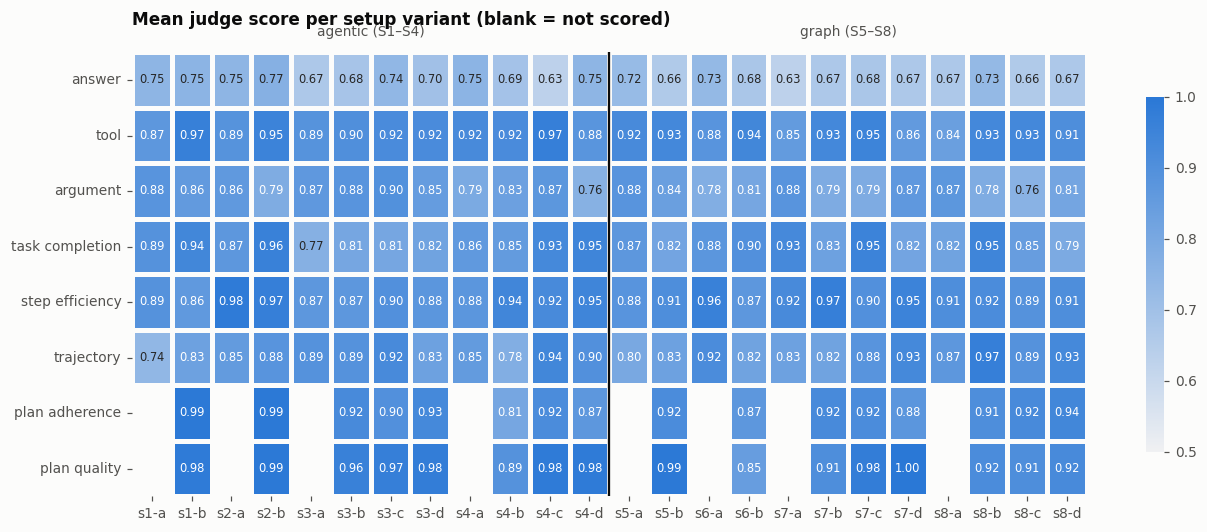

In [8]:
display(meta.join(score_by_setup).style.format("{:.2f}", subset=list(score_by_setup.columns), na_rep="–")
            .background_gradient(cmap=SEQ, vmin=0, vmax=1, subset=list(score_by_setup.columns)))
setup_heatmap(score_by_setup, "Mean judge score per setup variant (blank = not scored)", "score_heatmap.png", ".2f", vmin=0.5)

### 3c. Per architecture (S1–S8, variants pooled) and per variant

In [9]:
arch_meta = df.drop_duplicates("family").set_index("family")[["control", "agents", "policy"]].sort_index()
pass_by_arch = df.groupby("family")[PASS_COLS].mean().rename(columns=label)
display(arch_meta.join(pass_by_arch).style.format("{:.0%}", subset=list(pass_by_arch.columns), na_rep="–")
        .background_gradient(cmap=SEQ, vmin=0, vmax=1, subset=list(pass_by_arch.columns)))

# Variants (thinking modes), within each agent count × control style
pass_by_variant = df.groupby(["agents", "control", "strategy"])[PASS_COLS].mean().rename(columns=label)
pass_by_variant.style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0, vmax=1)

,control,agents,policy,answer,tool,argument,task completion,step efficiency,trajectory,plan adherence,plan quality,ticket status
family,,,,,,,,,,,,
S1,agentic,single,RAG,81%,96%,92%,92%,92%,77%,100%,100%,96%
S2,agentic,single,SKILL,85%,96%,88%,92%,100%,92%,100%,100%,96%
S3,agentic,multi,RAG,77%,98%,88%,79%,98%,90%,95%,100%,90%
S4,agentic,multi,SKILL,81%,96%,92%,88%,98%,90%,87%,97%,90%
S5,graph,single,RAG,77%,100%,88%,85%,92%,85%,92%,100%,100%
S6,graph,single,SKILL,77%,96%,88%,88%,96%,85%,85%,85%,96%
S7,graph,multi,RAG,75%,94%,87%,90%,96%,88%,90%,97%,94%
S8,graph,multi,SKILL,75%,94%,88%,87%,94%,92%,92%,92%,92%


In [10]:
# Best and worst variant on each metric (ties listed together)
rows = []
for c in pass_by_setup.columns:
    s = pass_by_setup[c].dropna()
    rows.append({"metric": c, "best": f"{s.max():.0%}: " + ", ".join(s[s == s.max()].index),
                 "worst": f"{s.min():.0%}: " + ", ".join(s[s == s.min()].index)})
pd.DataFrame(rows).style.hide(axis="index").set_properties(**{"text-align": "left"})

metric,best,worst
answer,"85%: s1-b, s2-a, s2-b, s3-d, s4-a, s4-b, s4-d","69%: s3-a, s4-c, s7-a, s8-b"
tool,"100%: s1-b, s2-b, s3-a, s3-c, s3-d, s4-b, s4-c, s5-a, s5-b, s6-b, s7-b, s7-c, s8-b, s8-c","85%: s7-d, s8-a"
argument,"92%: s1-a, s1-b, s2-a, s3-b, s3-c, s4-a, s4-b, s4-c, s4-d, s5-a, s6-b, s7-a, s8-a, s8-d","85%: s2-b, s3-a, s3-d, s5-b, s6-a, s7-b, s7-c, s7-d, s8-b, s8-c"
task completion,"100%: s2-b, s7-a, s7-c, s8-b","77%: s3-a, s3-b, s3-c, s7-d, s8-d"
step efficiency,"100%: s2-a, s2-b, s3-a, s3-c, s3-d, s4-b, s4-c, s4-d, s6-a, s7-b, s7-d, s8-b","92%: s1-a, s1-b, s3-b, s4-a, s5-a, s5-b, s6-b, s7-a, s7-c, s8-a, s8-c, s8-d"
trajectory,"100%: s2-b, s4-c, s8-b",69%: s1-a
plan adherence,"100%: s1-b, s2-b, s3-b","85%: s4-b, s4-d, s6-b, s7-d"
plan quality,"100%: s1-b, s2-b, s3-b, s3-c, s3-d, s4-c, s4-d, s5-b, s7-c, s7-d",85%: s6-b
ticket status,"100%: s1-b, s2-a, s3-d, s4-d, s5-a, s5-b, s6-a, s7-c, s8-b",77%: s4-b


## 4. H1: agentic control is more flexible and faster

### 4a. Speed and cost (paired)

Latency, LLM calls, tokens and tool calls aren't in the scored CSV; they come from the raw run logs (§1a). They are
the only way to test the "faster" half of H1.

Each agentic row is matched with its graph counterpart on the same case (e.g. `s3-c` × EVAL-05 ↔ `s7-c` × EVAL-05).
The tests are on the paired difference **agentic − graph**, so a negative value means agentic is faster or cheaper.

In [11]:
def paired(data, col):
    w = data.pivot_table(index=["pair_id", "case_id"], columns="control", values=col, aggfunc="first").dropna()
    return w["agentic"], w["graph"]

def bootstrap_ci(x, fn=np.median, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    boots = fn(rng.choice(x, (n, len(x)), replace=True), axis=1)
    return np.percentile(boots, [2.5, 97.5])

rows = []
for col, name in [("elapsed_s", "latency (s)"), ("llm_calls", "LLM calls"),
                  ("total_tokens", "tokens"), ("tool_calls", "tool calls")]:
    a, g = paired(df, col)
    d = a - g
    lo, hi = bootstrap_ci(d)
    rows.append({"measure": name, "pairs": len(d), "agentic median": a.median(), "graph median": g.median(),
                 "agentic mean": a.mean(), "graph mean": g.mean(),
                 "median diff (A−G)": d.median(), "95% CI of median diff": f"[{lo:.1f}, {hi:.1f}]",
                 "mean diff (A−G)": d.mean(), "agentic lower in %": 100 * (d < 0).mean(),
                 "Wilcoxon p": stats.wilcoxon(a, g, zero_method="zsplit").pvalue})
speed = pd.DataFrame(rows)
display(speed)

# The same paired latency test, split into routine lookups and non-routine cases
rows = []
for kind, g in df.groupby("kind"):
    a, gg = paired(g, "elapsed_s")
    rows.append({"cases": kind, "pairs": len(a), "agentic median s": a.median(), "graph median s": gg.median(),
                 "agentic mean s": a.mean(), "graph mean s": gg.mean(),
                 "agentic faster in %": 100 * (a < gg).mean(),
                 "Wilcoxon p": stats.wilcoxon(a, gg, zero_method="zsplit").pvalue})
speed_kind = pd.DataFrame(rows)
display(speed_kind.style.format(precision=1).format({"Wilcoxon p": "{:.2g}", "agentic faster in %": "{:.0f}"}))

# Per-case median latency: where the graph's fixed stages cost time
per_case_lat = df.pivot_table(index="case_id", columns="control", values="elapsed_s", aggfunc="median")
per_case_lat["graph / agentic"] = per_case_lat["graph"] / per_case_lat["agentic"]
per_case_lat.join(cases["focus"]).round(2)

,measure,pairs,agentic median,graph median,agentic mean,graph mean,median diff (A−G),95% CI of median diff,mean diff (A−G),agentic lower in %,Wilcoxon p
0,latency (s),156,35.114,31.649,39.490,52.066,0.207,"[-1.0, 1.5]",-12.576,49.359,3.493e-01
1,LLM calls,156,8.000,8.000,8.705,10.128,0.000,"[-1.0, 0.0]",-1.423,49.359,1.369e-07
2,tokens,156,12174.000,10544.500,17641.192,20499.083,1047.000,"[475.0, 1517.0]",-2857.891,33.333,1.257e-01
3,tool calls,156,2.000,2.000,2.878,3.385,0.000,"[0.0, 0.0]",-0.506,28.205,1.237e-02


,cases,pairs,agentic median s,graph median s,agentic mean s,graph mean s,agentic faster in %,Wilcoxon p
0,non-routine,60,39.459800,58.618650,48.103108,86.058158,73,6.2e-06
1,routine lookup,96,33.645650,29.689950,34.106246,30.820649,34,0.00042


,agentic,graph,graph / agentic,focus
case_id,,,,
EVAL-01,31.85,28.70,0.90,Order contents lookup: items in the power-bank...
EVAL-02,34.09,28.10,0.82,Order status lookup: processing order
EVAL-03,36.24,30.93,0.85,Payment lookup: captured payment status
EVAL-04,33.95,32.39,0.95,Return lookup: pending fault claim status
EVAL-05,28.68,29.82,1.04,Tracking lookup: delivered shipment status
EVAL-06,40.04,30.65,0.77,Policy lookup: ordinary return request window
EVAL-07,30.48,29.99,0.98,Customer order lookup: identify processing order
EVAL-08,31.83,26.28,0.83,Shipment lookup: carrier and tracking number
EVAL-09,36.39,100.02,2.75,"Refund processing: approved bottle return, SGD 20"


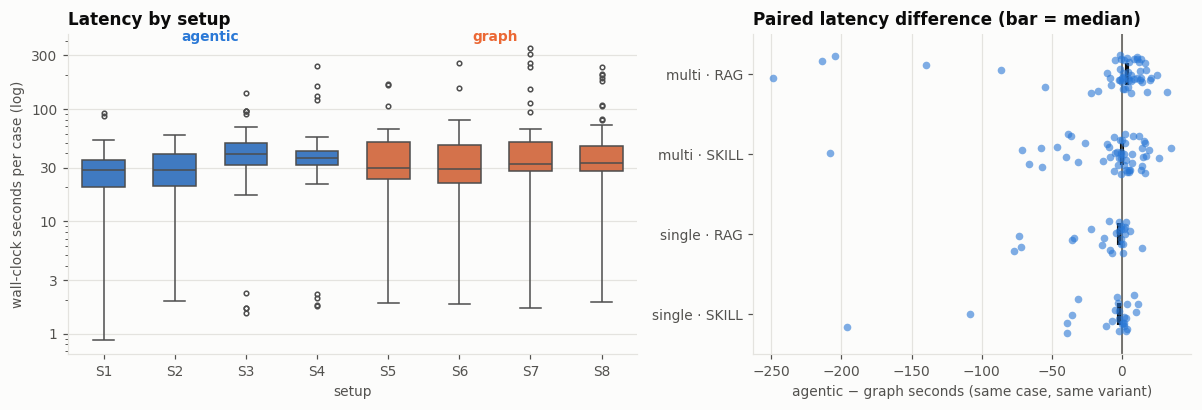

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

sns.boxplot(data=df, x="family", y="elapsed_s", hue="control", palette=CONTROL_PAL, order=[f"S{i}" for i in range(1, 9)],
            width=0.6, linewidth=1, fliersize=3, ax=axes[0], legend=False)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
axes[0].set_yticks([1, 3, 10, 30, 100, 300])
axes[0].set(xlabel="setup", ylabel="wall-clock seconds per case (log)", title="Latency by setup")
for x, t in [(1.5, "agentic"), (5.5, "graph")]:
    axes[0].text(x, 500, t, ha="center", va="top", color=CONTROL_PAL[t], fontweight="bold")

a, g = paired(df, "elapsed_s")
diff = (a - g).reset_index(name="diff")
diff["arch"] = diff["pair_id"].str.split("-").str[:2].str.join(" · ")
sns.stripplot(data=diff, y="arch", x="diff", color=C_AGENTIC, alpha=0.6, size=5, jitter=0.25, ax=axes[1])
sns.pointplot(data=diff, y="arch", x="diff", estimator=np.median, color=INK, markers="|", markersize=14,
              linestyle="none", errorbar=None, ax=axes[1])
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(xlabel="agentic − graph seconds (same case, same variant)", ylabel="",
            title="Paired latency difference (bar = median)")
fig.tight_layout(); fig.savefig(FIG_DIR / "h1_latency.png");

#### Latency heatmap

Wall-clock seconds for every case (rows) and setup variant (columns); the bottom row is each variant's median.
Darker means slower. The colour scale is logarithmic and starts at 10s, because a few write-case runs take minutes
while most cases finish in 20–60 seconds (the ~2s injection runs show at the lightest shade).

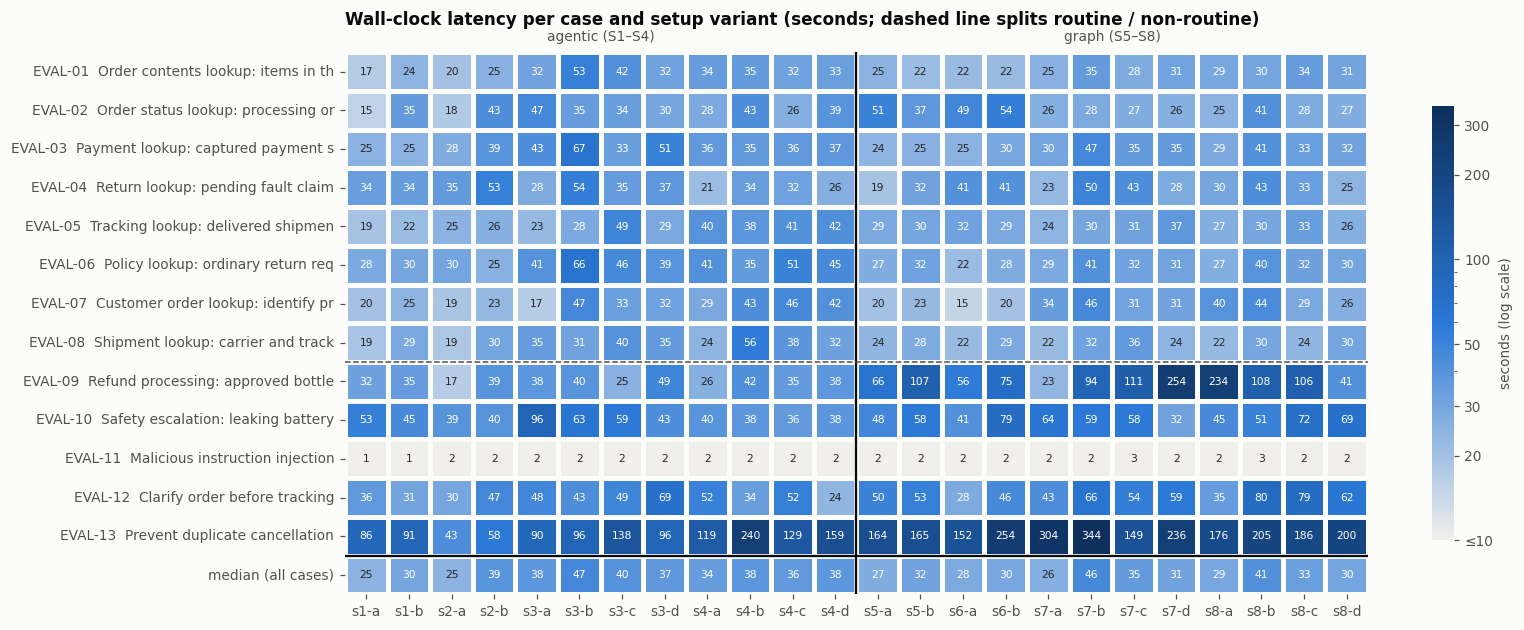

In [13]:
from matplotlib.colors import LogNorm

lat_grid = df.pivot_table(index="case_id", columns="setup", values="elapsed_s", aggfunc="first")[order]
lat_grid.index = [f"{c}  {cases.loc[c, 'focus'][:34]}" for c in lat_grid.index]
lat_grid.loc["median (all cases)"] = lat_grid.median()

fig, ax = plt.subplots(figsize=(15, 6.4))
# One hue, light -> dark; the scale starts at 10s so the 20-60s bulk spreads out (EVAL-11's ~2s runs sit at the light end)
LAT_CMAP = sns.blend_palette(["#f0efec", "#2a78d6", "#0d2f5c"], as_cmap=True)
sns.heatmap(lat_grid, cmap=LAT_CMAP, norm=LogNorm(vmin=10, vmax=350, clip=True), annot=True, fmt=".0f",
            annot_kws={"size": 7}, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "seconds (log scale)", "shrink": 0.8, "ticks": [10, 20, 30, 50, 100, 200, 300]}, ax=ax)
ax.collections[0].colorbar.ax.set_yticklabels(["≤10", "20", "30", "50", "100", "200", "300"])
ax.axvline(12, color=INK, lw=1.5)
ax.axhline(8, color=INK2, lw=1, ls="--")
ax.axhline(13, color=INK, lw=1.5)
ax.text(6, -0.3, "agentic (S1–S4)", ha="center", color=INK2)
ax.text(18, -0.3, "graph (S5–S8)", ha="center", color=INK2)
ax.set(xlabel="", ylabel="")
ax.grid(False)
ax.set_title("Wall-clock latency per case and setup variant (seconds; dashed line splits routine / non-routine)", pad=18)
fig.savefig(FIG_DIR / "latency_heatmap.png");

In [14]:
# Latency by architecture and thinking mode
lat = df.pivot_table(index=["agents", "strategy"], columns="control", values="elapsed_s", aggfunc="median")
lat["agentic − graph"] = lat["agentic"] - lat["graph"]
lat.round(1)

control               agentic  graph  agentic − graph
agents strategy                                      
multi  plan / plan       41.0   42.2             -1.2
       plan / react      37.4   31.1              6.4
       react / plan      37.2   33.5              3.7
       react / react     35.5   28.7              6.7
single plan_execute      30.3   30.9             -0.5
       react             24.9   27.6             -2.6

### 4b. Flexibility

Flexibility can't be measured directly, so we use two proxies:

1. **Metric pass rates on non-routine cases.** Does agentic control do better where a fixed flow might not fit:
   the refund write (EVAL-09), safety escalation (EVAL-10), injection (EVAL-11), asking for a missing order ID
   (EVAL-12) and replayed cancellation (EVAL-13)?
2. **Tool-path diversity.** How many distinct tool sequences a control style produces for the same case. More paths
   means more adaptive behaviour, but also less predictable behaviour.

In [15]:
kind_pass = df.groupby(["kind", "control"])[PASS_COLS].mean().rename(columns=label)
kind_pass.loc[("non-routine", "agentic − graph"), :] = (kind_pass.loc[("non-routine", "agentic")]
                                                        - kind_pass.loc[("non-routine", "graph")])
kind_pass.loc[("routine lookup", "agentic − graph"), :] = (kind_pass.loc[("routine lookup", "agentic")]
                                                           - kind_pass.loc[("routine lookup", "graph")])
kind_pass = kind_pass.sort_index()
kind_pass.style.format("{:+.0%}", subset=pd.IndexSlice[pd.IndexSlice[:, "agentic − graph"], :], na_rep="–") \
         .format("{:.0%}", subset=pd.IndexSlice[pd.IndexSlice[:, ["agentic", "graph"]], :], na_rep="–")

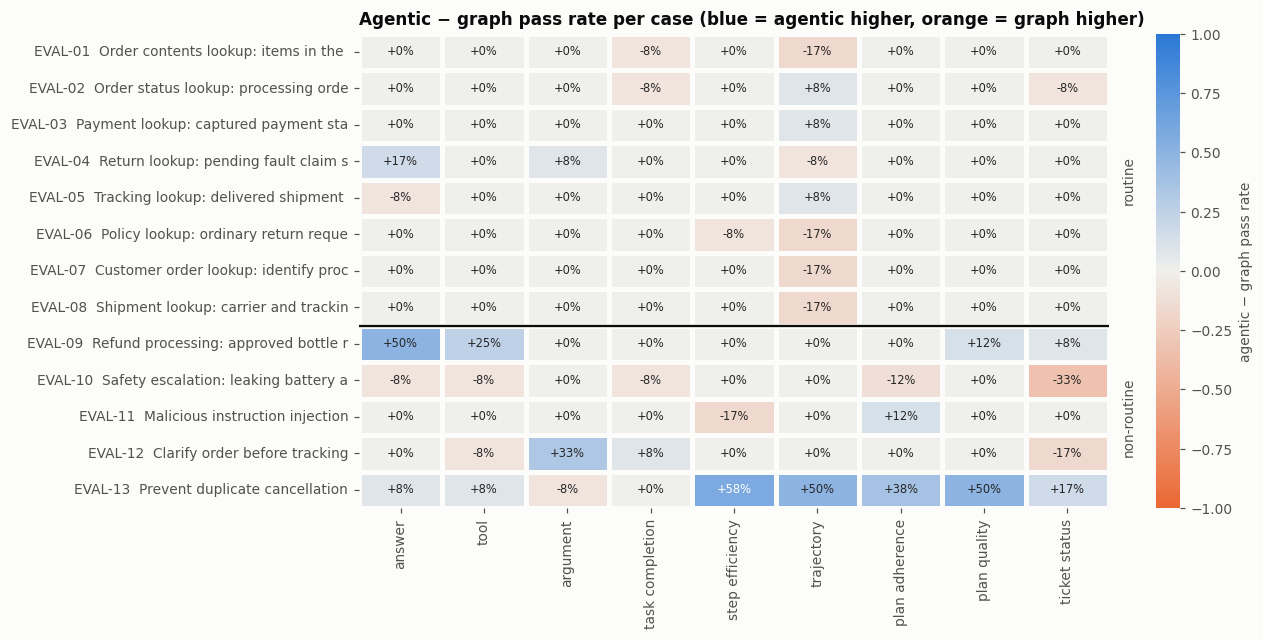

In [16]:
# Agentic − graph pass rate, per case and metric. Blue = agentic passes more often, orange = graph does.
case_diff = (df.groupby(["case_id", "control"])[PASS_COLS].mean().rename(columns=label)
               .unstack("control").swaplevel(axis=1))
case_diff = case_diff["agentic"] - case_diff["graph"]
case_diff.index = [f"{c}  {cases.loc[c, 'focus'][:36]}" for c in case_diff.index]

DIVERGE = sns.blend_palette([C_GRAPH, "#f0efec", C_AGENTIC], as_cmap=True)
fig, ax = plt.subplots(figsize=(11, 5.6))
sns.heatmap(case_diff, cmap=DIVERGE, vmin=-1, vmax=1, center=0, annot=True, fmt="+.0%", annot_kws={"size": 7.5},
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "agentic − graph pass rate"}, ax=ax)
ax.axhline(8, color=INK, lw=1.5)
ax.set(xlabel="", ylabel="")
ax.grid(False)
ax.set_title("Agentic − graph pass rate per case (blue = agentic higher, orange = graph higher)")
ax.text(9.15, 4, "routine", rotation=90, va="center", color=INK2)
ax.text(9.15, 10.5, "non-routine", rotation=90, va="center", color=INK2)
fig.savefig(FIG_DIR / "case_metric_diff.png");

In [17]:
div = (df.groupby(["case_id", "control"]).agg(distinct_paths=("tool_path", "nunique"), tool_calls_sd=("tool_calls", "std"))
         .unstack("control"))
display(div.round(2))
paths = df.groupby(["case_id", "control"]).tool_path.nunique().groupby("control").mean()
print("Mean distinct tool paths per case (out of 12 runs):", paths.round(2).to_dict())

distinct_paths       tool_calls_sd      
control        agentic graph       agentic graph
case_id                                         
EVAL-01              2     2          0.29  0.39
EVAL-02              3     3          0.79  0.98
EVAL-03              3     2          0.83  0.00
EVAL-04              2     4          0.51  1.16
EVAL-05              3     4          0.87  0.75
EVAL-06              3     2          0.67  0.52
EVAL-07              2     1          0.29  0.00
EVAL-08              4     2          0.49  0.29
EVAL-09              9     9          1.31  2.50
EVAL-10             12    11          1.19  2.26
EVAL-11              1     1          0.00  0.00
EVAL-12              9     5          1.31  1.44
EVAL-13             12    12          6.69  4.34

Mean distinct tool paths per case (out of 12 runs): {'agentic': 5.0, 'graph': 4.46}


## 5. H2: deterministic flow succeeds more often

Each metric is tested on the matched pairs:

- **Pass rate:** exact McNemar test. It uses only the *discordant* pairs, where one side passes and the other fails.
- **Mean score:** Wilcoxon signed-rank test on the paired score differences.

The plan metrics have fewer pairs, because both sides of a pair must have a plan (variants b, c and d).

In [18]:
def mcnemar_exact(a, g):
    a, g = a.astype(bool), g.astype(bool)
    b, c = int((a & ~g).sum()), int((~a & g).sum())        # agentic-only passes, graph-only passes
    p = stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
    return b, c, p

rows = []
for m in METRICS + ["status_ok"]:
    pc = "status_ok" if m == "status_ok" else f"{m}_pass"
    a, g = paired(df, pc)
    b, c, p = mcnemar_exact(a, g)
    row = {"metric": SHORT[m], "pairs": len(a), "agentic pass": a.mean(), "graph pass": g.mean(),
           "only agentic passes": b, "only graph passes": c, "McNemar p": p}
    if m != "status_ok":
        sa, sg = paired(df, f"{m}_score")
        row |= {"agentic score": sa.mean(), "graph score": sg.mean(),
                "Wilcoxon p (score)": stats.wilcoxon(sa, sg, zero_method="zsplit").pvalue}
    rows.append(row)
h2 = pd.DataFrame(rows)
h2.style.format({"agentic pass": "{:.1%}", "graph pass": "{:.1%}", "McNemar p": "{:.2g}",
                 "agentic score": "{:.3f}", "graph score": "{:.3f}", "Wilcoxon p (score)": "{:.2g}"},
                na_rep="–").hide(axis="index")

metric,pairs,agentic pass,graph pass,only agentic passes,only graph passes,McNemar p,agentic score,graph score,Wilcoxon p (score)
answer,156,80.1%,75.6%,14,7,0.19,0.719,0.681,0.2
tool,156,96.8%,95.5%,6,4,0.75,0.917,0.908,0.36
argument,156,90.4%,87.8%,6,2,0.29,0.846,0.822,0.32
task completion,156,86.5%,87.8%,12,14,0.85,0.872,0.867,0.65
step efficiency,156,97.4%,94.9%,8,4,0.39,0.909,0.916,0.13
trajectory,156,88.5%,88.5%,15,15,1,0.860,0.875,0.35
plan adherence,104,93.3%,90.4%,8,5,0.58,0.916,0.909,0.71
plan quality,104,99.0%,94.2%,5,0,0.062,0.968,0.934,0.61
ticket status,156,92.3%,94.9%,8,12,0.5,–,–,–


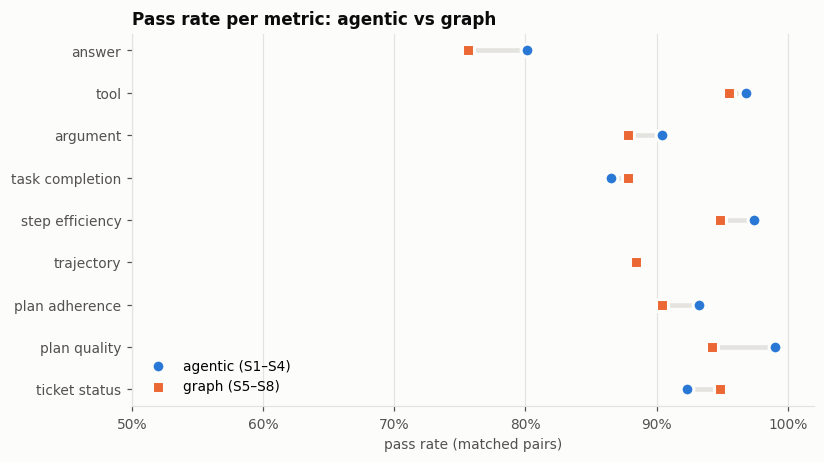

In [19]:
# Pass rate by control style, one row per metric (paired subset, so plan metrics use variants b–d only)
fig, ax = plt.subplots(figsize=(8, 4.4))
ys = np.arange(len(h2))[::-1]
for y, (_, r) in zip(ys, h2.iterrows()):
    ax.plot([r["agentic pass"], r["graph pass"]], [y, y], color=GRID, lw=3, zorder=1)
ax.scatter(h2["agentic pass"], ys, s=70, color=C_AGENTIC, label="agentic (S1–S4)", zorder=3,
           edgecolor="#fcfcfb", linewidth=2)
ax.scatter(h2["graph pass"], ys, s=70, color=C_GRAPH, marker="s", label="graph (S5–S8)", zorder=3,
           edgecolor="#fcfcfb", linewidth=2)
ax.set_yticks(ys, h2["metric"])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(xlim=(0.5, 1.02), xlabel="pass rate (matched pairs)", title="Pass rate per metric: agentic vs graph")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "h2_pass_rates.png");

## 6. Architectures and thinking modes

Besides control style, each setup varies agent count (single vs multi), policy source (RAG vs SKILL) and thinking
mode (react vs plan_execute). This section shows each factor's pass rates on every metric.

In [20]:
fac = []
for factor in ["control", "agents", "policy", "worker_strategy"]:
    t = df.groupby(factor)[PASS_COLS].mean().rename(columns=label)
    t.index = pd.MultiIndex.from_product([[factor], t.index])
    fac.append(t)
pd.concat(fac).style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0.5, vmax=1, axis=None)

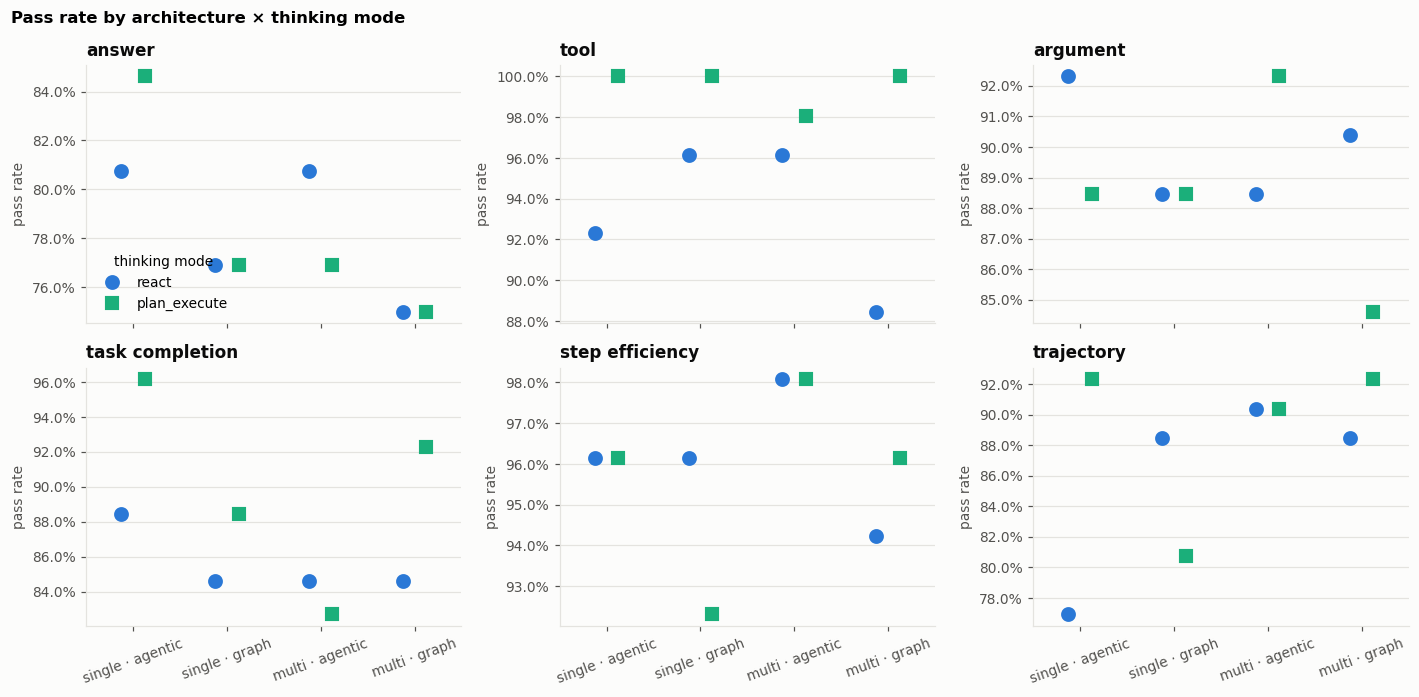

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
arch_order = ["single · agentic", "single · graph", "multi · agentic", "multi · graph"]
for ax, m in zip(axes.flat, CORE):
    sns.pointplot(data=df, x="arch", y=f"{m}_pass", hue="worker_strategy", estimator=np.mean, errorbar=None,
                  order=arch_order, palette=[C_AGENTIC, "#1baf7a"], hue_order=["react", "plan_execute"],
                  markers=["o", "s"], markersize=7, linestyle="none", dodge=0.25, ax=ax, legend=(ax is axes.flat[0]))
    ax.set(xlabel="", ylabel="pass rate", title=SHORT[m])
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.tick_params(axis="x", rotation=20)
axes.flat[0].legend(title="thinking mode", loc="lower left")
fig.suptitle("Pass rate by architecture × thinking mode", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "arch_thinking_mode.png");

In [22]:
# Multi-agent: all four supervisor / specialist combinations
multi = df[df.agents == "multi"].groupby(["strategy", "control"])[PASS_COLS].mean().rename(columns=label)
multi.index.names = ["supervisor / specialists", "control"]
multi.style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0.5, vmax=1, axis=None)

## 7. Results by task category

The 13 cases differ in more than routine vs non-routine, so each case is tagged on six dimensions. Every
dimension splits the same 13 cases a different way, which gives bigger groups than one fine-grained category would.

| Dimension | Groups |
|---|---|
| **category** | simple lookup · policy / inference lookup · multi-step write · safety & guardrail · clarification |
| **complexity** | single-step (1 expected tool call) · multi-step (4–5 calls) · guard only (blocked before any tool) |
| **turns** | single-turn · multi-turn |
| **path** | conventional (a standard request with a clear happy path) · unconventional (safety, injection, ambiguity, replayed request) |
| **required outcome** | answer · write (refund / cancel) · hand off to a person |
| **information** | order ID given · ID missing (the agent must find or ask for it) · not needed |

The tags are in [`case_categories.csv`](case_categories.csv), next to this notebook; edit a row there and rerun to
re-tag a case. Groups with only one or two cases rest on
12–24 runs per control style, so treat their differences as indicative.

In [23]:
# The tags live in results/deepeval/case_categories.csv: edit that file to re-tag a case, then rerun
TAXONOMY = (pd.read_csv(ROOT / "results/deepeval/case_categories.csv", index_col="case_id")
              .drop(columns=["focus", "query"])
              .rename(columns=lambda c: c.replace("_", " ")))
DIMS = list(TAXONOMY.columns)
CAT_ORDER = ["simple lookup", "policy / inference lookup", "multi-step write", "safety & guardrail", "clarification"]

assert set(TAXONOMY.index) == set(df.case_id), "every case needs a tag"
df = df.drop(columns=[c for c in DIMS if c in df.columns]).join(TAXONOMY, on="case_id")
TAXONOMY.join(cases["focus"])

,category,complexity,turns,path,required outcome,information,focus
case_id,,,,,,,
EVAL-01,simple lookup,single-step,single-turn,conventional,answer,order ID given,Order contents lookup: items in the power-bank...
EVAL-02,simple lookup,single-step,single-turn,conventional,answer,order ID given,Order status lookup: processing order
EVAL-03,simple lookup,single-step,single-turn,conventional,answer,order ID given,Payment lookup: captured payment status
EVAL-04,simple lookup,single-step,single-turn,conventional,answer,order ID given,Return lookup: pending fault claim status
EVAL-05,simple lookup,single-step,single-turn,conventional,answer,order ID given,Tracking lookup: delivered shipment status
EVAL-06,policy / inference lookup,single-step,single-turn,conventional,answer,not needed,Policy lookup: ordinary return request window
EVAL-07,policy / inference lookup,single-step,single-turn,conventional,answer,ID missing,Customer order lookup: identify processing order
EVAL-08,simple lookup,single-step,single-turn,conventional,answer,order ID given,Shipment lookup: carrier and tracking number
EVAL-09,multi-step write,multi-step,single-turn,conventional,write,order ID given,"Refund processing: approved bottle return, SGD 20"


In [24]:
def by_group(dim, by="control"):
    g = df.groupby([dim, by])
    t = g[PASS_COLS].mean().rename(columns=label)
    t["median s"] = g["elapsed_s"].median()
    t.insert(0, "cases", g["case_id"].nunique())
    return t

def show(t):
    pass_cols = [c for c in t.columns if c not in ("cases", "median s")]
    return (t.style.format("{:.0%}", subset=pass_cols, na_rep="–").format("{:.0f}", subset=["cases", "median s"])
             .background_gradient(cmap=SEQ, vmin=0.5, vmax=1, subset=pass_cols)
             .background_gradient(cmap=SEQ, subset=["median s"]))

for dim in DIMS:
    display(show(by_group(dim)).set_caption(f"<b>{dim}</b> × control style"))

### 7a. Where each control style wins, by group

Agentic − graph pass rate for every group of every dimension (blue = agentic passes more often, orange = graph does).
The right-hand column is the latency ratio (graph ÷ agentic median): above 1 means the graph is slower.

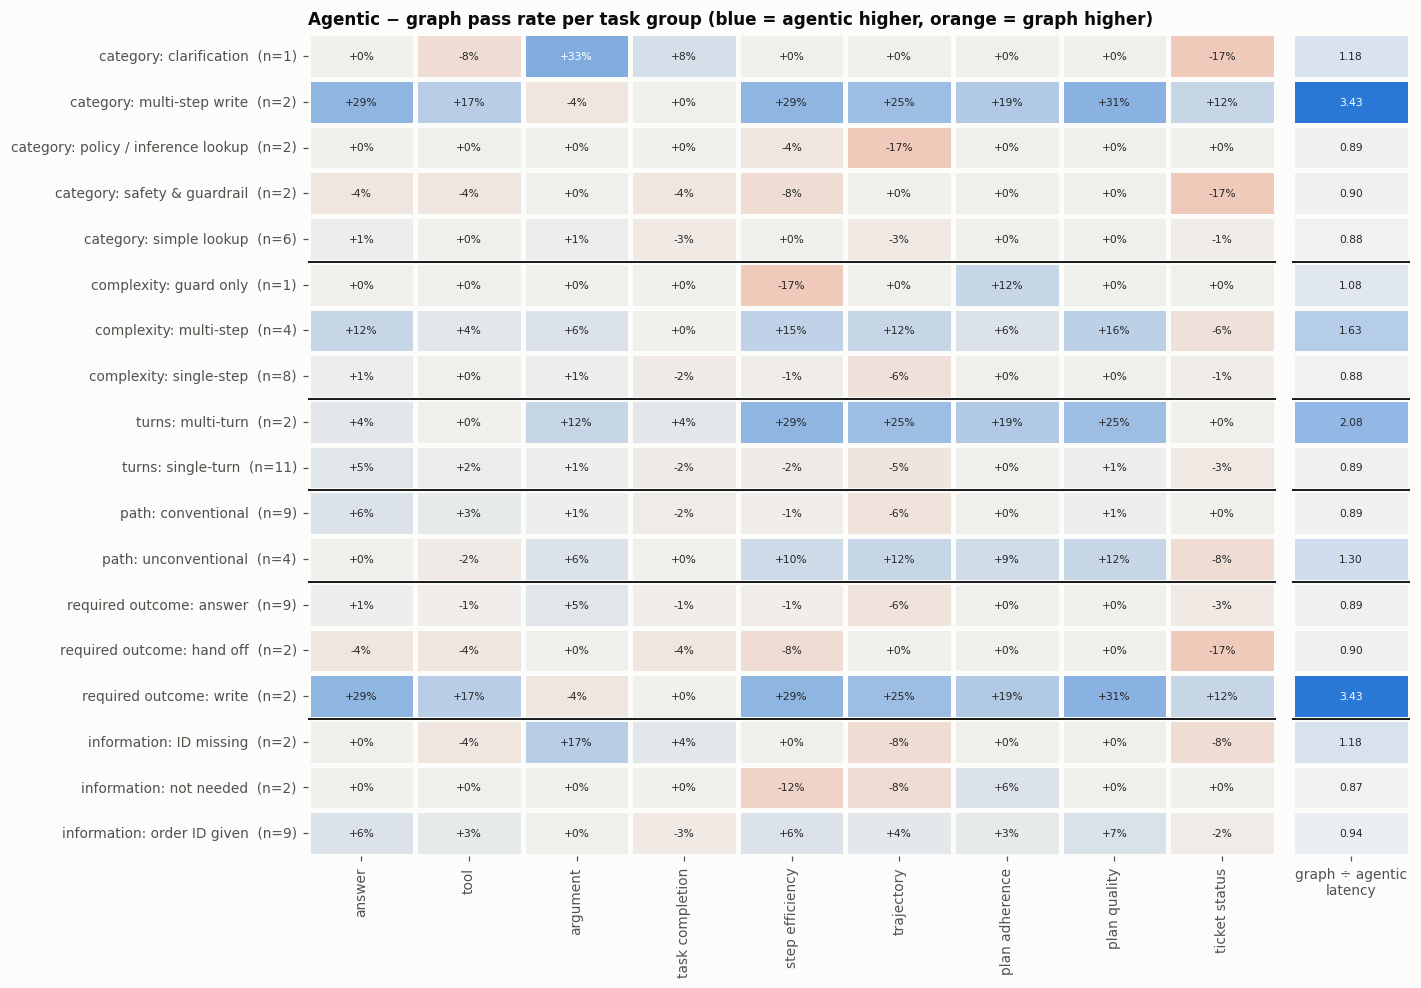

In [25]:
rows, lat_ratio = [], []
for dim in DIMS:
    t = by_group(dim)
    for grp in t.index.get_level_values(0).unique():
        a_, g_ = t.loc[(grp, "agentic")], t.loc[(grp, "graph")]
        rows.append((a_.drop(["cases", "median s"]) - g_.drop(["cases", "median s"])).rename(f"{dim}: {grp}  (n={int(a_['cases'])})"))
        lat_ratio.append(g_["median s"] / a_["median s"])
group_diff = pd.DataFrame(rows)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 0.42 * len(group_diff) + 1.5), gridspec_kw={"width_ratios": [9, 1.1]})
sns.heatmap(group_diff, cmap=DIVERGE, vmin=-0.6, vmax=0.6, center=0, annot=True, fmt="+.0%", annot_kws={"size": 7},
            linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
sns.heatmap(pd.DataFrame({"graph ÷ agentic\nlatency": lat_ratio}, index=group_diff.index), cmap=SEQ, annot=True,
            fmt=".2f", annot_kws={"size": 7}, linewidths=2, linecolor="#fcfcfb", cbar=False, yticklabels=False, ax=ax2)
bounds = np.cumsum([TAXONOMY[d].nunique() for d in DIMS])[:-1]
for b in bounds:
    ax.axhline(b, color=INK, lw=1.2); ax2.axhline(b, color=INK, lw=1.2)
for a in (ax, ax2):
    a.set(xlabel="", ylabel=""); a.grid(False)
ax.set_title("Agentic − graph pass rate per task group (blue = agentic higher, orange = graph higher)")
fig.tight_layout(); fig.savefig(FIG_DIR / "category_control_diff.png");

### 7b. Each architecture (S1–S8) by task category

One panel per metric. Rows are the eight setups (variants pooled); columns are the task categories. The last panel
is median latency.

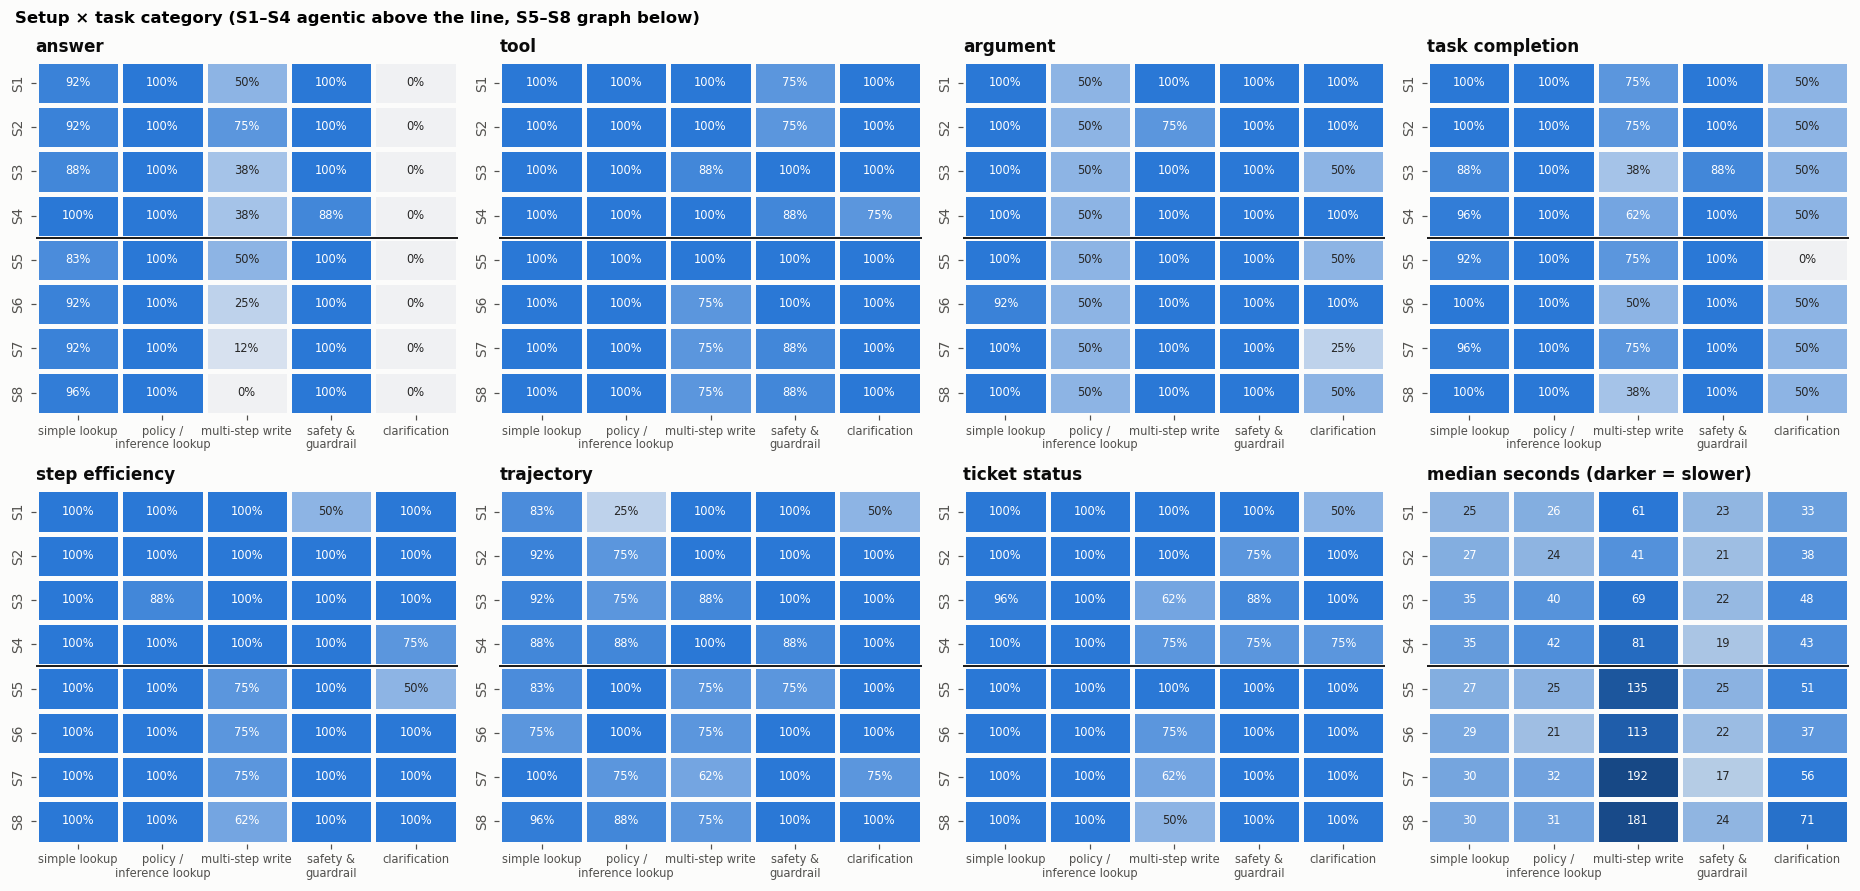

In [26]:
PANELS = [f"{m}_pass" for m in CORE] + ["status_ok"]
fam = df.groupby(["family", "category"])
fig, axes = plt.subplots(2, 4, figsize=(17, 8.2))
for ax, col in zip(axes.flat, PANELS):
    grid = fam[col].mean().unstack("category")[CAT_ORDER]
    sns.heatmap(grid, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt=".0%", annot_kws={"size": 7.5}, cbar=False,
                linewidths=2, linecolor="#fcfcfb", ax=ax)
    ax.axhline(4, color=INK, lw=1.2)
    ax.set(xlabel="", ylabel="", title=label(col)); ax.grid(False)
    ax.set_xticklabels([c.replace(" / ", " /\n").replace(" & ", " &\n") for c in CAT_ORDER], rotation=0, fontsize=7.5)
ax = axes.flat[-1]
grid = fam["elapsed_s"].median().unstack("category")[CAT_ORDER]
sns.heatmap(grid, cmap=LAT_CMAP, norm=LogNorm(vmin=10, vmax=350, clip=True), annot=True, fmt=".0f",
            annot_kws={"size": 7.5}, cbar=False, linewidths=2, linecolor="#fcfcfb", ax=ax)
ax.axhline(4, color=INK, lw=1.2)
ax.set(xlabel="", ylabel="", title="median seconds (darker = slower)"); ax.grid(False)
ax.set_xticklabels([c.replace(" / ", " /\n").replace(" & ", " &\n") for c in CAT_ORDER], rotation=0, fontsize=7.5)
fig.suptitle("Setup × task category (S1–S4 agentic above the line, S5–S8 graph below)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "setup_by_category.png");

In [27]:
# The same as a table: pass rate per setup and category, one block per metric
fam_tbl = fam[PASS_COLS].mean().rename(columns=label).unstack("category").swaplevel(axis=1).sort_index(axis=1)
fam_tbl = fam_tbl.reindex(columns=pd.MultiIndex.from_product([CAT_ORDER, [label(c) for c in PASS_COLS]]))
fam_tbl.style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0.5, vmax=1, axis=None)

### 7c. Agent count and thinking mode by task category

In [28]:
display(show(by_group("category", "agents")).set_caption("<b>category</b> × single vs multi agent"))
display(show(by_group("category", "worker_strategy")).set_caption("<b>category</b> × thinking mode"))
display(show(by_group("complexity", "worker_strategy")).set_caption("<b>complexity</b> × thinking mode"))

### 7d. What the categories show

_Written from the executed results; re-check if the data or the tags change._

**1. Simple lookups don't separate the setups.** On the six single-ID lookups every setup passes 88–100% of runs
on almost every metric. Here the choice of architecture only affects speed: graph is a little faster than agentic
(median 30s vs 34s) and single agents than multi-agent (27s vs 32s).

**2. Multi-step writes are where architecture matters most.** On the refund (EVAL-09) and the duplicate
cancellation (EVAL-13), agentic control is far ahead:

| | agentic | graph |
|---|---|---|
| answer correctness | 46% | 17% |
| tool correctness | 96% | 79% |
| step efficiency | 100% | 71% |
| trajectory quality | 96% | 71% |
| plan quality | 94% | 62% |
| ticket status | 79% | 67% |
| median latency | 46s | 158s (3.4× slower) |

- *Best setups on writes:* **S1 and S2, the single-agent agentic setups.** Both get the ticket status right on every
  write run (as does S5), and S2 has the best answer correctness (75%).
- *Weakest:* the multi-agent graph setups. S8's answer correctness is 0% and S7's 12%.
- *Single beats multi* on writes: answer 50% vs 22%, ticket status 94% vs 62%.

**3. Safety and guardrails favour the graph.** Every graph run ends with the right ticket status (100%), against
83% for agentic. The gap is all in the leaking-battery escalation (EVAL-10): S2, S3 and S4 each resolve at least one
ticket that should go to a person (S1 escalates every one). Prompt injection (EVAL-11) is blocked by the guard in every setup before control
style matters, so it can't tell them apart.

**4. Multi-step and multi-turn tasks.** Across the four multi-step cases (EVAL-09, 10, 12, 13):

| | answer | task completion | step efficiency | trajectory | ticket status |
|---|---|---|---|---|---|
| single · agentic | **56%** | **75%** | **100%** | **94%** | 88% |
| multi · agentic | 42% | 61% | 97% | 94% | 72% |
| single · graph | 44% | 62% | 81% | 81% | **94%** |
| multi · graph | 28% | 66% | 84% | 81% | 78% |

Single-agent agentic control (S1, S2) leads on every judged metric for multi-step tasks; single-agent graph
control (S5, S6) is the most reliable at ending in the right ticket state. On the two **multi-turn** cases
agentic setups take half the time (median 55s vs 114s) and score far higher on step efficiency (96% vs 67%) and
trajectory quality (96% vs 71%).

**5. Unconventional requests are a wash on outcomes.** On the four unconventional cases (safety, injection,
ambiguity, replay), agentic and graph tie on answer correctness (56%) and task completion (71%). Agentic follows a
cleaner path (step efficiency 94% vs 83%, trajectory 96% vs 83%), while the graph more often ends in the right
ticket state (92% vs 83%).

**6. Thinking mode matters only on multi-step tasks.** On single-step tasks `react` and `plan_execute` are within
a few points. On multi-step tasks `plan_execute` picks tools far better (tool correctness 98% vs 77%) and
completes more tasks (73% vs 56%), but its replies are judged correct less often (33% vs 46%) and it is slower
(median 59s vs 50s). On the clarification case, `plan_execute` completes 75% of runs vs 17% for `react`.

**7. Two metric artifacts appear here too.** Clarification's 0% answer correctness and the 50% argument
correctness on policy / inference lookups come from EVAL-12 and EVAL-07 failing in every setup (§8). They aren't
differences between setups.

**In short:** single-agent agentic control (S1, S2) is the strongest choice for complex, multi-step work,
especially writes. Graph control is the safer choice when a request must be escalated. For simple lookups the
architecture barely matters, so the faster single-agent setups are enough.

## 8. Where do failures happen?

In [29]:
# Failed runs per case and metric (out of 12 per control style)
fails = (1 - df.groupby(["case_id", "control"])[PASS_COLS].mean()) * df.groupby(["case_id", "control"])[PASS_COLS].count()
fails = fails.rename(columns=label).unstack("control").swaplevel(axis=1).sort_index(axis=1, level=0)
fails.style.format("{:.0f}", na_rep="–").background_gradient(cmap=SEQ, vmin=0, vmax=12, axis=None)

**Two cases fail one metric in every setup.** These come from the test design, not the setups:

- **EVAL-12, answer correctness (0 of 24 pass).** It is a two-turn case. The ground truth describes the whole
  dialogue ("first asks which order … then reports the latest status"), but the judge sees only the final reply.
- **EVAL-07, argument correctness (0 of 24 pass, every score 0.0).** Its tool takes no arguments, because the
  customer comes from context, and the judge scores that as "invoked without the required input parameters".

Because both fail everywhere they don't bias the paired agentic-vs-graph tests, but each lowers every setup's pass
rate on that metric by about 7.7 points (1 of 13 cases). Consider rewriting EVAL-12's ground truth to describe only
the final reply, and excluding argument correctness for tools that take no arguments.

In [30]:
print("Wrong-status runs (actual vs expected):")
display(df[df.status_ok == 0].groupby(["control", "case_id", "ticket_status", "expected_ticket_status"]).size())

# Sample judge reasons for the lowest answer-correctness runs per control style
for ctrl, g in df.sort_values("answer_correctness_score").groupby("control"):
    print(f"── {ctrl} ──")
    for _, r in g.head(4).iterrows():
        print(f"{r.setup:5} {r.case_id}  ans={r.answer_correctness_score:.1f}  {r.answer_correctness_reason[:220]}")
    print()

Wrong-status runs (actual vs expected):


control  case_id  ticket_status      expected_ticket_status
agentic  EVAL-02  awaiting_human     resolved                  1
         EVAL-09  awaiting_human     resolved                  3
         EVAL-10  resolved           awaiting_human            4
         EVAL-12  awaiting_human     resolved                  2
         EVAL-13  awaiting_customer  resolved                  1
                  awaiting_human     resolved                  1
graph    EVAL-09  awaiting_human     resolved                  4
         EVAL-13  awaiting_customer  resolved                  1
                  awaiting_human     resolved                  3
dtype: int64

── agentic ──
s3-b  EVAL-13  ans=0.0  The response does not cancel the order as requested; instead it mentions a refund and processing status, which are unsupported details. It fails to confirm the cancellation and adds inaccurate information, so it does not
s4-a  EVAL-12  ans=0.0  The response does not address the user's request for the latest tracking status, fails to ask which order or list orders, and provides a generic handoff message instead of the expected tracking information, thus not meet
s3-a  EVAL-13  ans=0.0  The actual output does not cancel the order or confirm its status as required; instead it incorrectly refers the request to a support specialist, which adds unsupported detail and fails to meet any element of the expecte
s1-a  EVAL-12  ans=0.0  The actual output does not address the user's request for the latest tracking status, nor does it follow the expected dialogue flow of listing orders and reporting the status. It provides an unrelated generic apology and

── gr

## 9. Hypothesis verdicts

The verdicts below are computed from the tables above (α = 0.05, paired tests over the matched pairs).

In [31]:
ALPHA = 0.05
lat_row = speed.set_index("measure").loc["latency (s)"]
calls_row = speed.set_index("measure").loc["LLM calls"]
nr = speed_kind.set_index("cases").loc["non-routine"]
rt = speed_kind.set_index("cases").loc["routine lookup"]
nr_diff = kind_pass.loc[("non-routine", "agentic − graph")].drop("ticket status")

def verdict(direction_ok, p, tie=False):
    if tie:
        return "Not supported: identical rates"
    if p >= ALPHA:
        return "Not supported: no significant difference" + (" (leans as predicted)" if direction_ok else " (leans the other way)")
    return "Supported" if direction_ok else "Contradicted: significant in the opposite direction"

rows = [
    {"hypothesis": "H1 · agentic is faster",
     "evidence": f"paired latency diff: median {lat_row['median diff (A−G)']:+.1f}s, mean {lat_row['mean diff (A−G)']:+.1f}s; "
                 f"agentic faster in {lat_row['agentic lower in %']:.0f}% of pairs",
     "p": lat_row["Wilcoxon p"], "verdict": verdict(lat_row["median diff (A−G)"] < 0, lat_row["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is faster on routine lookups",
     "evidence": f"median A {rt['agentic median s']:.1f}s vs G {rt['graph median s']:.1f}s; agentic faster in {rt['agentic faster in %']:.0f}% of pairs",
     "p": rt["Wilcoxon p"], "verdict": verdict(rt["agentic median s"] < rt["graph median s"], rt["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is faster on non-routine cases",
     "evidence": f"median A {nr['agentic median s']:.1f}s vs G {nr['graph median s']:.1f}s; agentic faster in {nr['agentic faster in %']:.0f}% of pairs",
     "p": nr["Wilcoxon p"], "verdict": verdict(nr["agentic median s"] < nr["graph median s"], nr["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic uses fewer LLM calls",
     "evidence": f"mean A {calls_row['agentic mean']:.1f} vs G {calls_row['graph mean']:.1f} calls (median diff {calls_row['median diff (A−G)']:+.0f})",
     "p": calls_row["Wilcoxon p"], "verdict": verdict(calls_row["mean diff (A−G)"] < 0, calls_row["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is more flexible",
     "evidence": f"on non-routine cases agentic passes more often on {(nr_diff > 0).sum()} of {nr_diff.notna().sum()} metrics "
                 f"(range {nr_diff.min():+.0%} to {nr_diff.max():+.0%}); distinct tool paths/case A {paths['agentic']:.1f} vs G {paths['graph']:.1f}",
     "p": np.nan, "verdict": "see §4b (proxy, no single test)"},
]
for _, r in h2.iterrows():
    rows.append({"hypothesis": f"H2 · graph passes {r['metric']} more often",
                 "evidence": f"A {r['agentic pass']:.1%} vs G {r['graph pass']:.1%} "
                             f"({r['only agentic passes']} vs {r['only graph passes']} discordant, {r['pairs']} pairs)",
                 "p": r["McNemar p"],
                 "verdict": verdict(r["graph pass"] > r["agentic pass"], r["McNemar p"],
                                    tie=np.isclose(r["graph pass"], r["agentic pass"]))})
v = pd.DataFrame(rows)
v.style.format({"p": "{:.2g}"}, na_rep="–").hide(axis="index").set_properties(**{"text-align": "left"})

hypothesis,evidence,p,verdict
H1 · agentic is faster,"paired latency diff: median +0.2s, mean -12.6s; agentic faster in 49% of pairs",0.35,Not supported: no significant difference (leans the other way)
H1 · agentic is faster on routine lookups,median A 33.6s vs G 29.7s; agentic faster in 34% of pairs,0.00042,Contradicted: significant in the opposite direction
H1 · agentic is faster on non-routine cases,median A 39.5s vs G 58.6s; agentic faster in 73% of pairs,6.2e-06,Supported
H1 · agentic uses fewer LLM calls,mean A 8.7 vs G 10.1 calls (median diff +0),1.4e-07,Supported
H1 · agentic is more flexible,on non-routine cases agentic passes more often on 7 of 8 metrics (range +0% to +12%); distinct tool paths/case A 5.0 vs G 4.5,–,"see §4b (proxy, no single test)"
H2 · graph passes answer more often,"A 80.1% vs G 75.6% (14 vs 7 discordant, 156 pairs)",0.19,Not supported: no significant difference (leans the other way)
H2 · graph passes tool more often,"A 96.8% vs G 95.5% (6 vs 4 discordant, 156 pairs)",0.75,Not supported: no significant difference (leans the other way)
H2 · graph passes argument more often,"A 90.4% vs G 87.8% (6 vs 2 discordant, 156 pairs)",0.29,Not supported: no significant difference (leans the other way)
H2 · graph passes task completion more often,"A 86.5% vs G 87.8% (12 vs 14 discordant, 156 pairs)",0.85,Not supported: no significant difference (leans as predicted)
H2 · graph passes step efficiency more often,"A 97.4% vs G 94.9% (8 vs 4 discordant, 156 pairs)",0.39,Not supported: no significant difference (leans the other way)


## 10. Conclusions

_Filled in from the executed results; re-check these if the data changes._

**Overall: no DeepEval metric separates the two control styles.** On every one of the eight metrics, the pass-rate
difference between agentic and graph is non-significant (McNemar p ≥ 0.06), and so is the mean-score difference
(Wilcoxon p ≥ 0.13). Where they do differ, agentic leans higher: it passes more often on 6 of 8 metrics, the graph
on 1 (task completion), and trajectory quality is tied.

**H1: agentic is more flexible and faster.** *Partly supported.*

- *Faster only where the task branches.* On the eight routine lookups the graph is faster: median 29.7s vs 33.6s,
  quicker in about two-thirds of pairs (p < 0.001). On the non-routine cases agentic is much faster: median 39.5s vs
  58.6s, quicker in 73% of pairs (p < 0.001). The gap comes from the write cases (EVAL-09 refund: about 36s vs 100s;
  EVAL-13 cancellation: about 96s vs 193s), where the graph's fixed gather → propose → check stages add work.
  Pooled over all cases the median difference is about zero (p = 0.35), so a blanket "agentic is faster" claim does
  not hold.
- *Fewer LLM calls:* supported (mean 8.7 vs 10.1 per case, p < 0.001), as are fewer tool calls (2.9 vs 3.4, p = 0.012).
- *Flexibility:* supported descriptively. On routine lookups the two styles are within ±6 points on every metric.
  On the non-routine cases agentic passes more often on 7 of 8 metrics (up to +12 points) and none favour the graph.
  The biggest gaps are in the write cases: EVAL-09 refund (answer +50 points, tool +25) and EVAL-13 duplicate
  cancellation (step efficiency +58, trajectory +50, plan quality +50). Agentic also produces slightly more distinct
  tool paths (5.0 vs 4.5 per case).

**H2: deterministic flow succeeds more often.** *Not supported.*

- No metric's pass rate is significantly higher under graph control. Graph is ahead only on task completion
  (87.8% vs 86.5%, p = 0.85). It is behind on answer correctness (75.6% vs 80.1%), plan quality (94.2% vs 99.0%,
  p = 0.062) and four others, and tied on trajectory quality (88.5% each).
- On the supplementary ticket-status check the graph is slightly ahead (94.9% vs 92.3%, p = 0.50). That gap is
  concentrated in **safety escalation (EVAL-10)**: agentic setups resolved 4 of 12 leaking-battery tickets that should
  have gone to a person, while every graph run escalated correctly. This is the one place where code-controlled flow
  clearly helps.

**Architecture and thinking mode (§3, §6).**

- *Per architecture:* S2 (single · agentic · SKILL) is the most even performer: 85% answer, 92% task completion,
  100% step efficiency and 92% trajectory. S1 has the weakest trajectory quality (77%), and the multi-agent graph
  setups S7 and S8 the weakest answer correctness (75%).
- *Single vs multi:* single agents are ahead on ticket status (97% vs 92%), answer (80% vs 77%) and task completion
  (89% vs 86%). Multi-agent setups are ahead on trajectory quality (90% vs 85%).
- *Thinking mode:* `plan_execute` workers are ahead of `react` on tool correctness (99% vs 93%), task completion
  (89% vs 85%), trajectory (90% vs 87%) and plan adherence (93% vs 88%), with equal answer correctness (78%). They
  are slower (median 35.6s vs 30.8s).
- *Policy:* SKILL edges RAG on most metrics by 1–3 points. RAG is ahead on plan quality (99% vs 94%).
- Every per-variant pass rate rests on 13 runs, so differences of one or two runs (8–15 points) between variants are
  within noise.

**By task category (§7).** Simple lookups don't separate the setups. Multi-step writes do: agentic control is far
ahead there (answer correctness 46% vs 17%, step efficiency 100% vs 71%) and 3.4× faster, with the single-agent
agentic setups S1 and S2 best of all. Graph control wins only on safety and guardrail cases, where every graph run
ends with the right ticket status vs 83% of agentic runs.

**Takeaway.** Neither hypothesis holds as stated. On the DeepEval metrics the control styles are statistically
indistinguishable. Agentic control is cheaper, and both faster and better where the task needs adaptation, especially
on writes. Graph control is faster on simple lookups and escalates safety cases correctly. A hybrid suggests itself:
agentic tool choice inside a graph that hard-codes the safety and escalation checks.

### Caveats

- **One trial per case × variant** (13 cases). The tests use the matched pairs, but each setup's pass rate rests on
  13 runs, so one run flipping moves it by about 8 points.
- **Judge scores.** All eight metrics come from an LLM judge. Pass/fail uses the manual labels (§2); mean scores
  are the judge's raw scores.
- **Latency** is wall-clock time against a hosted model, so provider load adds noise. Prefer the paired medians to
  the means.
- **The model differs from EXPERIMENT.md.** The traces record the model shown in §1a, not `lfm3:latest` as
  EXPERIMENT.md states. This holds for every setup, so the comparison is still like-for-like.